In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df = pd.read_excel("Telco_customer_churn.xlsx")
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [3]:
df.shape

(7043, 33)

In [4]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

In [6]:
for column in df.columns:
    print(column)

CustomerID
Count
Country
State
City
Zip Code
Lat Long
Latitude
Longitude
Gender
Senior Citizen
Partner
Dependents
Tenure Months
Phone Service
Multiple Lines
Internet Service
Online Security
Online Backup
Device Protection
Tech Support
Streaming TV
Streaming Movies
Contract
Paperless Billing
Payment Method
Monthly Charges
Total Charges
Churn Label
Churn Value
Churn Score
CLTV
Churn Reason


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [8]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [9]:
df['Churn Value'].value_counts()

Churn Value
0    5174
1    1869
Name: count, dtype: int64

In [10]:
df['Churn Value'].value_counts(normalize=True)*100

Churn Value
0    73.463013
1    26.536987
Name: proportion, dtype: float64

In [16]:
df[['Churn Label', 'Churn Value']].head(5)

,Churn Label,Churn Value
0,Yes,1
1,Yes,1
2,Yes,1
3,Yes,1
4,Yes,1


In [18]:
df[["Churn Label", "Churn Value", "Churn Score", "Churn Reason"]].head()

,Churn Label,Churn Value,Churn Score,Churn Reason
0,Yes,1,86,Competitor made better offer
1,Yes,1,67,Moved
2,Yes,1,86,Moved
3,Yes,1,84,Moved
4,Yes,1,89,Competitor had better devices


In [20]:
categorical_cols= df.select_dtypes(include='object').columns

for column in categorical_cols:
    print(f'\n{column}')
    print(df[column].unique())


CustomerID
['3668-QPYBK' '9237-HQITU' '9305-CDSKC' ... '2234-XADUH' '4801-JZAZL'
 '3186-AJIEK']

Country
['United States']

State
['California']

City
['Los Angeles' 'Beverly Hills' 'Huntington Park' ... 'Standish' 'Tulelake'
 'Olympic Valley']

Lat Long
['33.964131, -118.272783' '34.059281, -118.30742' '34.048013, -118.293953'
 ... '40.346634, -120.386422' '41.813521, -121.492666'
 '39.191797, -120.212401']

Gender
['Male' 'Female']

Senior Citizen
['No' 'Yes']

Partner
['No' 'Yes']

Dependents
['No' 'Yes']

Phone Service
['Yes' 'No']

Multiple Lines
['No' 'Yes' 'No phone service']

Internet Service
['DSL' 'Fiber optic' 'No']

Online Security
['Yes' 'No' 'No internet service']

Online Backup
['Yes' 'No' 'No internet service']

Device Protection
['No' 'Yes' 'No internet service']

Tech Support
['No' 'Yes' 'No internet service']

Streaming TV
['No' 'Yes' 'No internet service']

Streaming Movies
['No' 'Yes' 'No internet service']

Contract
['Month-to-month' 'Two year' 'One year']

Paper

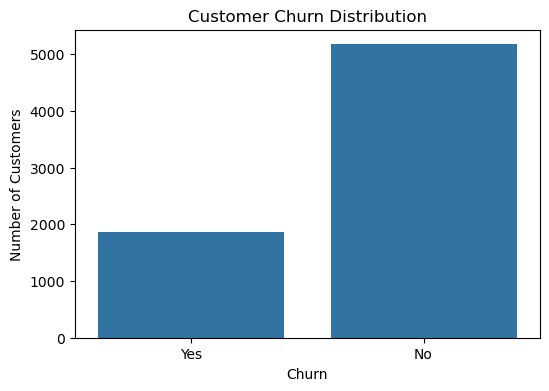

In [26]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn Label')
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
#plt.xticks(rotation = 50)
plt.show()

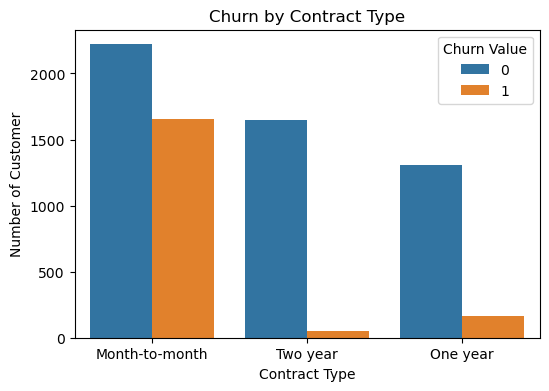

In [28]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Contract', hue='Churn Value')
plt.title("Churn by Contract Type")
plt.xlabel('Contract Type')
plt.ylabel("Number of Customer")
plt.show()

In [29]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

df["Total Charges"].isnull().sum()

np.int64(11)

In [30]:
drop_columns = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "Lat Long",
    "Churn Label",
    "Churn Score",
    "Churn Reason",
]

df_clean = df.drop(columns=[col for col in drop_columns if col in df.columns])

df_clean.head()

,City,Zip Code,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,...,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,CLTV
0,Los Angeles,90003,33.964131,-118.272783,Male,No,No,No,2,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,3239
1,Los Angeles,90005,34.059281,-118.307420,Female,No,No,Yes,2,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,2701
2,Los Angeles,90006,34.048013,-118.293953,Female,No,No,Yes,8,Yes,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1,5372
3,Los Angeles,90010,34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,...,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1,5003
4,Los Angeles,90015,34.039224,-118.266293,Male,No,No,Yes,49,Yes,...,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1,5340


In [31]:
X = df_clean.drop(columns=["Churn Value"])
y = df_clean["Churn Value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 24)
Target shape: (7043,)


In [33]:
X.columns.tolist()

['City',
 'Zip Code',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'CLTV']

In [34]:
y.value_counts()

Churn Value
0    5174
1    1869
Name: count, dtype: int64

In [36]:
y.value_counts(normalize = True)*100

Churn Value
0    73.463013
1    26.536987
Name: proportion, dtype: float64

In [37]:
for column in X.select_dtypes(include="object").columns:
    print(f"\n{column}")
    print(X[column].unique())


City
['Los Angeles' 'Beverly Hills' 'Huntington Park' ... 'Standish' 'Tulelake'
 'Olympic Valley']

Gender
['Male' 'Female']

Senior Citizen
['No' 'Yes']

Partner
['No' 'Yes']

Dependents
['No' 'Yes']

Phone Service
['Yes' 'No']

Multiple Lines
['No' 'Yes' 'No phone service']

Internet Service
['DSL' 'Fiber optic' 'No']

Online Security
['Yes' 'No' 'No internet service']

Online Backup
['Yes' 'No' 'No internet service']

Device Protection
['No' 'Yes' 'No internet service']

Tech Support
['No' 'Yes' 'No internet service']

Streaming TV
['No' 'Yes' 'No internet service']

Streaming Movies
['No' 'Yes' 'No internet service']

Contract
['Month-to-month' 'Two year' 'One year']

Paperless Billing
['Yes' 'No']

Payment Method
['Mailed check' 'Electronic check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
